# Part 1: Hyperparameters and GAN training

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# Reproducibility
seed = 285
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

assert torch.cuda.is_available(), "Select the 1 GPU DataHub environment."
device = torch.device("cuda")

torch.backends.cudnn.benchmark = True

# Paths
root = Path("/home/zih050/private")
data_dir = root / "wikiart_small"
output_dir = root / "results_v3"
output_dir.mkdir(parents=True, exist_ok=True)

# Hyperparameters
image_size = 64
latent_dim = 128
batch_size = 64
epochs = 60

learning_rate = 1e-4
lambda_gp = 10
critic_steps = 3

# Dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3)
])

train_dataset = datasets.ImageFolder(
    data_dir / "train",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    data_dir / "test",
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("GPU:", torch.cuda.get_device_name(0))
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training epochs:", epochs)
print("Results directory:", output_dir)

GPU: NVIDIA GeForce GTX 1080 Ti
Training images: 10121
Testing images: 2536
Training epochs: 60
Results directory: /home/zih050/private/results_v3


In [2]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


class Critic(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.LayerNorm([128, 16, 16]),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.LayerNorm([256, 8, 8]),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1),
            nn.LayerNorm([512, 4, 4]),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 1, 4, 1, 0)
        )

    def forward(self, x):
        return self.net(x).flatten()


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)

        if m.bias is not None:
            nn.init.zeros_(m.bias)

    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


def gradient_penalty(critic, real, fake):
    n = real.size(0)

    alpha = torch.rand(n, 1, 1, 1, device=device)

    interpolated = (
        alpha * real + (1 - alpha) * fake
    ).requires_grad_(True)

    scores = critic(interpolated)

    gradients = torch.autograd.grad(
        outputs=scores,
        inputs=interpolated,
        grad_outputs=torch.ones_like(scores),
        create_graph=True
    )[0]

    gradients = gradients.reshape(n, -1)

    penalty = (
        (gradients.norm(2, dim=1) - 1) ** 2
    ).mean()

    return penalty


G = Generator().to(device)
C = Critic().to(device)

G.apply(init_weights)
C.apply(init_weights)

# Check model outputs
G.eval()
C.eval()

with torch.no_grad():
    z = torch.randn(2, latent_dim, 1, 1, device=device)
    fake = G(z)

    print("Generator output:", fake.shape)
    print("Critic output:", C(fake).shape)

G.train()
C.train()

print("Generator parameters:", sum(p.numel() for p in G.parameters()))
print("Critic parameters:", sum(p.numel() for p in C.parameters()))

Generator output: torch.Size([2, 3, 64, 64])
Critic output: torch.Size([2])
Generator parameters: 3806080
Critic parameters: 2879425


In [3]:
# Optimizers
opt_G = torch.optim.Adam(
    G.parameters(),
    lr=learning_rate,
    betas=(0.0, 0.9)
)

opt_C = torch.optim.Adam(
    C.parameters(),
    lr=learning_rate,
    betas=(0.0, 0.9)
)

checkpoint_path = output_dir / "wgan_gp_latest.pt"

history = {
    "G": [],
    "C": [],
    "GP": []
}

start_epoch = 0
resume_training = True

# Resume V3 training if interrupted
if checkpoint_path.exists() and resume_training:
    state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    G.load_state_dict(state["G"])
    C.load_state_dict(state["C"])

    opt_G.load_state_dict(state["opt_G"])
    opt_C.load_state_dict(state["opt_C"])

    history = state["history"]
    start_epoch = state["epoch"]

    print("Resuming at epoch:", start_epoch + 1)

else:
    print("Starting WGAN-GP training from scratch.")


# Fixed noise for consistent visual comparisons
fixed_z = torch.randn(
    16, latent_dim, 1, 1,
    generator=torch.Generator().manual_seed(seed + 1)
).to(device)


for epoch in range(start_epoch, epochs):
    G.train()
    C.train()

    total_g = 0.0
    total_c = 0.0
    total_gp = 0.0

    g_updates = 0

    for step, (real, _) in enumerate(train_loader):
        real = real.to(device, non_blocking=True)
        n = real.size(0)

        # -------------------------
        # Train Critic
        # -------------------------
        C.requires_grad_(True)
        opt_C.zero_grad(set_to_none=True)

        z = torch.randn(
            n, latent_dim, 1, 1, device=device
        )

        with torch.no_grad():
            fake = G(z)

        real_scores = C(real)
        fake_scores = C(fake)

        gp = gradient_penalty(C, real, fake)

        loss_C = (
            fake_scores.mean()
            - real_scores.mean()
            + lambda_gp * gp
        )

        loss_C.backward()
        opt_C.step()

        total_c += loss_C.item()
        total_gp += gp.item()

        # -------------------------
        # Train Generator
        # -------------------------
        if (step + 1) % critic_steps == 0:
            C.requires_grad_(False)
            opt_G.zero_grad(set_to_none=True)

            z = torch.randn(
                n, latent_dim, 1, 1, device=device
            )

            generated = G(z)

            loss_G = -C(generated).mean()

            loss_G.backward()
            opt_G.step()

            total_g += loss_G.item()
            g_updates += 1

    avg_g = total_g / max(g_updates, 1)
    avg_c = total_c / len(train_loader)
    avg_gp = total_gp / len(train_loader)

    history["G"].append(avg_g)
    history["C"].append(avg_c)
    history["GP"].append(avg_gp)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"G: {avg_g:.4f} | "
        f"C: {avg_c:.4f} | "
        f"GP: {avg_gp:.4f}"
    )

    # Checkpoint
    state = {
        "epoch": epoch + 1,
        "G": G.state_dict(),
        "C": C.state_dict(),
        "opt_G": opt_G.state_dict(),
        "opt_C": opt_C.state_dict(),
        "history": history
    }

    torch.save(state, checkpoint_path)

    with open(output_dir / "training_history.json", "w") as f:
        json.dump(history, f, indent=2)

    # Save model and images every 10 epochs
    if (epoch + 1) % 10 == 0:
        torch.save(
            state,
            output_dir / f"wgan_gp_epoch_{epoch+1:02d}.pt"
        )

        G.eval()

        with torch.no_grad():
            samples = G(fixed_z).cpu()

        save_image(
            samples,
            output_dir / f"epoch_{epoch+1:02d}.png",
            nrow=4,
            normalize=True,
            value_range=(-1, 1)
        )

G.eval()
C.eval()

print("\nWGAN-GP training completed.")
print("Total epochs:", len(history["G"]))
print("Checkpoint:", checkpoint_path)

Starting WGAN-GP training from scratch.
Epoch 01/60 | G: 26.4686 | C: -24.5515 | GP: 1.0082
Epoch 02/60 | G: 22.0081 | C: -14.2264 | GP: 0.3971
Epoch 03/60 | G: 26.5019 | C: -15.4504 | GP: 0.4734
Epoch 04/60 | G: 21.0211 | C: -12.5973 | GP: 0.3481
Epoch 05/60 | G: 18.2827 | C: -9.7656 | GP: 0.2393
Epoch 06/60 | G: 23.6045 | C: -9.2990 | GP: 0.2377
Epoch 07/60 | G: 22.4551 | C: -8.2209 | GP: 0.2041
Epoch 08/60 | G: 24.7582 | C: -7.2976 | GP: 0.1895
Epoch 09/60 | G: 25.5605 | C: -7.6949 | GP: 0.1965
Epoch 10/60 | G: 25.2909 | C: -6.8669 | GP: 0.1568
Epoch 11/60 | G: 20.3615 | C: -6.5479 | GP: 0.1227
Epoch 12/60 | G: 19.0745 | C: -6.3388 | GP: 0.1306
Epoch 13/60 | G: 18.7651 | C: -5.6498 | GP: 0.1212
Epoch 14/60 | G: 18.1385 | C: -5.3642 | GP: 0.1157
Epoch 15/60 | G: 19.7434 | C: -5.2141 | GP: 0.1142
Epoch 16/60 | G: 19.4987 | C: -5.3720 | GP: 0.1219
Epoch 17/60 | G: 16.5013 | C: -5.2526 | GP: 0.1180
Epoch 18/60 | G: 13.9345 | C: -5.1389 | GP: 0.1237
Epoch 19/60 | G: 14.3671 | C: -5.2486 

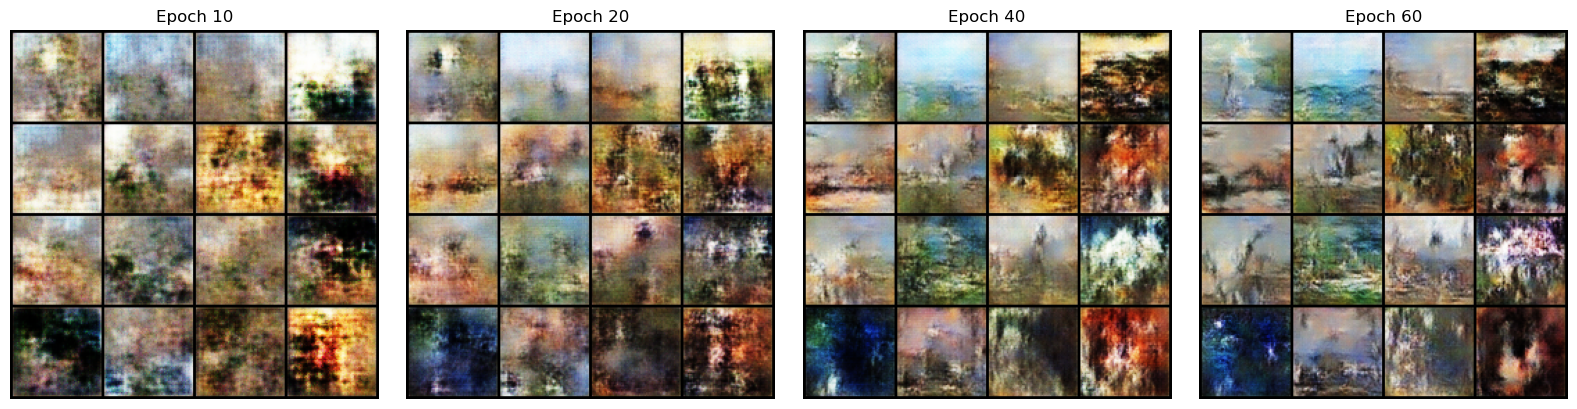

In [4]:
from PIL import Image

compare_epochs = [10, 20, 40, 60]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, epoch in zip(axes, compare_epochs):
    img = Image.open(output_dir / f"epoch_{epoch:02d}.png")
    ax.imshow(img)
    ax.set_title(f"Epoch {epoch}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# Part 2: Training loss curves

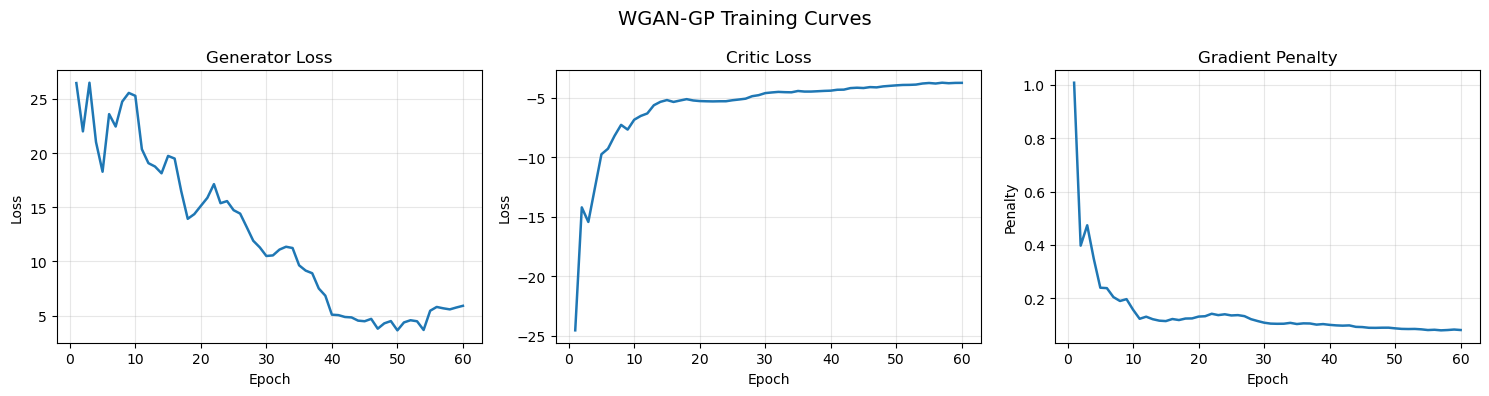

Total epochs: 60
Final Generator Loss: 5.9025
Final Critic Loss: -3.7705
Final Gradient Penalty: 0.0806


In [5]:
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("/home/zih050/private/results_v3")

# Load saved training history
with open(output_dir / "training_history.json", "r") as f:
    history = json.load(f)

epochs = np.arange(1, len(history["G"]) + 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

titles = [
    "Generator Loss",
    "Critic Loss",
    "Gradient Penalty"
]

keys = ["G", "C", "GP"]

for ax, key, title in zip(axes, keys, titles):
    ax.plot(epochs, history[key], linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss" if key != "GP" else "Penalty")
    ax.grid(alpha=0.3)

plt.suptitle("WGAN-GP Training Curves", fontsize=14)
plt.tight_layout()

plt.savefig(
    output_dir / "training_losses.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total epochs:", len(epochs))
print(f"Final Generator Loss: {history['G'][-1]:.4f}")
print(f"Final Critic Loss: {history['C'][-1]:.4f}")
print(f"Final Gradient Penalty: {history['GP'][-1]:.4f}")

# Part 3: Inception and FID scores

In [6]:
import json
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import inception_v3, Inception_V3_Weights
from ignite.metrics import FID

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
root = Path("/home/zih050/private")
data_dir = root / "wikiart_small"
output_dir = root / "results_v3"

latent_dim = 128
seed = 285
eval_batch_size = 16

# Test dataset
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

test_dataset = datasets.ImageFolder(
    data_dir / "test", transform=transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=eval_batch_size,
    shuffle=False,
    num_workers=2
)

# V3 generator architecture
class GeneratorEval(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512), nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


G = GeneratorEval().to(device)

# InceptionV3
inception = inception_v3(
    weights=Inception_V3_Weights.IMAGENET1K_V1
).to(device).eval()

classifier = inception.fc
inception.fc = nn.Identity()


def prepare_inception(x):
    x = (x + 1) / 2

    x = F.interpolate(
        x, size=(299, 299),
        mode="bilinear",
        align_corners=False,
        antialias=True
    )

    mean = x.new_tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = x.new_tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

    return (x - mean) / std


# Compute real features once
real_features = []

print("Extracting real image features...")

with torch.no_grad():
    for real, _ in test_loader:
        real = real.to(device)
        features = inception(prepare_inception(real))
        real_features.append(features.cpu())

real_features = torch.cat(real_features)

# Same latent vectors for all checkpoints
fixed_latents = torch.randn(
    len(test_dataset), latent_dim, 1, 1,
    generator=torch.Generator().manual_seed(seed + 100)
)

checkpoints = {
    40: output_dir / "wgan_gp_epoch_40.pt",
    50: output_dir / "wgan_gp_epoch_50.pt",
    60: output_dir / "wgan_gp_epoch_60.pt"
}

scores = {}

# Evaluate each checkpoint
for epoch, path in checkpoints.items():

    print(f"\nEvaluating Epoch {epoch}...")

    state = torch.load(
        path, map_location=device, weights_only=False
    )

    assert state["epoch"] == epoch

    G.load_state_dict(state["G"])
    G.eval()

    fid = FID(
        num_features=2048,
        feature_extractor=nn.Identity(),
        device="cpu"
    )

    probabilities = []
    offset = 0

    with torch.no_grad():
        for batch_idx, (real, _) in enumerate(test_loader):
            n = real.size(0)

            z = fixed_latents[offset:offset+n].to(device)
            fake = G(z)

            fake_features = inception(
                prepare_inception(fake)
            ).cpu()

            fid.update((
                fake_features,
                real_features[offset:offset+n]
            ))

            logits = classifier(fake_features.to(device))
            probabilities.append(
                torch.softmax(logits, dim=1).cpu()
            )

            offset += n

            if (batch_idx + 1) % 40 == 0:
                print(f"  Processed {offset}/{len(test_dataset)} images")

    print("  Computing FID...")

    fid_score = float(fid.compute())

    p = torch.cat(probabilities).clamp_min(1e-12)
    p_mean = p.mean(dim=0).clamp_min(1e-12)

    is_score = torch.exp(
        (p * (p.log() - p_mean.log())).sum(dim=1).mean()
    ).item()

    scores[epoch] = {
        "FID_2048": fid_score,
        "Inception_Score": is_score
    }

    print(f"Epoch {epoch} FID: {fid_score:.4f}")
    print(f"Epoch {epoch} IS:  {is_score:.4f}")

    # Save completed scores after every checkpoint
    with open(output_dir / "evaluation_progress.json", "w") as f:
        json.dump(scores, f, indent=4)


# Final comparison
print("\n===== V3 Evaluation Results =====")

for epoch in checkpoints:
    print(
        f"Epoch {epoch} | "
        f"FID: {scores[epoch]['FID_2048']:.4f} | "
        f"IS: {scores[epoch]['Inception_Score']:.4f}"
    )

print("\nV1 Baseline | FID: 116.8773 | IS: 2.8385")

# Select best checkpoint by FID
selected_epoch = min(
    scores,
    key=lambda e: scores[e]["FID_2048"]
)

print(f"\nSelected V3 checkpoint: Epoch {selected_epoch}")

# Load selected generator for Part 4
selected_state = torch.load(
    checkpoints[selected_epoch],
    map_location=device,
    weights_only=False
)

G.load_state_dict(selected_state["G"])
G.eval()

# Restore training history
with open(output_dir / "training_history.json") as f:
    history = json.load(f)

# Save final results
results = {
    "model": "WGAN-GP",
    "dataset": "WikiArt Impressionism",
    "train_size": 10121,
    "test_size": len(test_dataset),
    "image_size": 64,
    "latent_dim": latent_dim,
    "batch_size": 64,
    "epochs_trained": 60,
    "selected_epoch": selected_epoch,
    "learning_rate": 0.0001,
    "lambda_gp": 10,
    "critic_steps": 3,
    "evaluation_samples": len(test_dataset),
    "fid_features": 2048,
    "scores": scores,
    "history": history
}

with open(output_dir / "results.json", "w") as f:
    json.dump(results, f, indent=4)

# Save selected generator separately
torch.save(
    {
        "epoch": selected_epoch,
        "G": G.state_dict()
    },
    output_dir / "selected_generator.pt"
)

del inception, classifier, fid, real_features
if device.type == "cuda":
    torch.cuda.empty_cache()

print("\nEvaluation completed.")
print("Results saved to:", output_dir / "results.json")

Extracting real image features...

Evaluating Epoch 40...
  Processed 640/2536 images
  Processed 1280/2536 images
  Processed 1920/2536 images
  Computing FID...
Epoch 40 FID: 159.1297
Epoch 40 IS:  1.9986

Evaluating Epoch 50...
  Processed 640/2536 images
  Processed 1280/2536 images
  Processed 1920/2536 images
  Computing FID...
Epoch 50 FID: 140.3466
Epoch 50 IS:  2.1192

Evaluating Epoch 60...
  Processed 640/2536 images
  Processed 1280/2536 images
  Processed 1920/2536 images
  Computing FID...
Epoch 60 FID: 127.1088
Epoch 60 IS:  2.2022

===== V3 Evaluation Results =====
Epoch 40 | FID: 159.1297 | IS: 1.9986
Epoch 50 | FID: 140.3466 | IS: 2.1192
Epoch 60 | FID: 127.1088 | IS: 2.2022

V1 Baseline | FID: 116.8773 | IS: 2.8385

Selected V3 checkpoint: Epoch 60

Evaluation completed.
Results saved to: /home/zih050/private/results_v3/results.json


# Part 4: Example of generated images

Loaded WGAN-GP V3, Epoch: 60


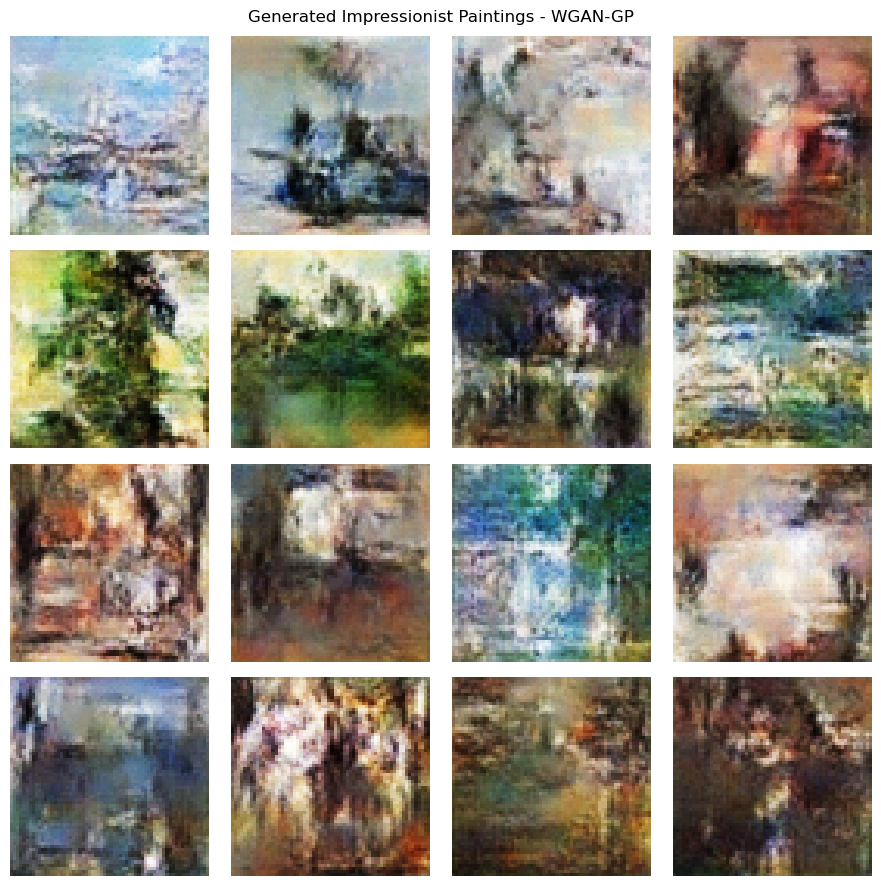

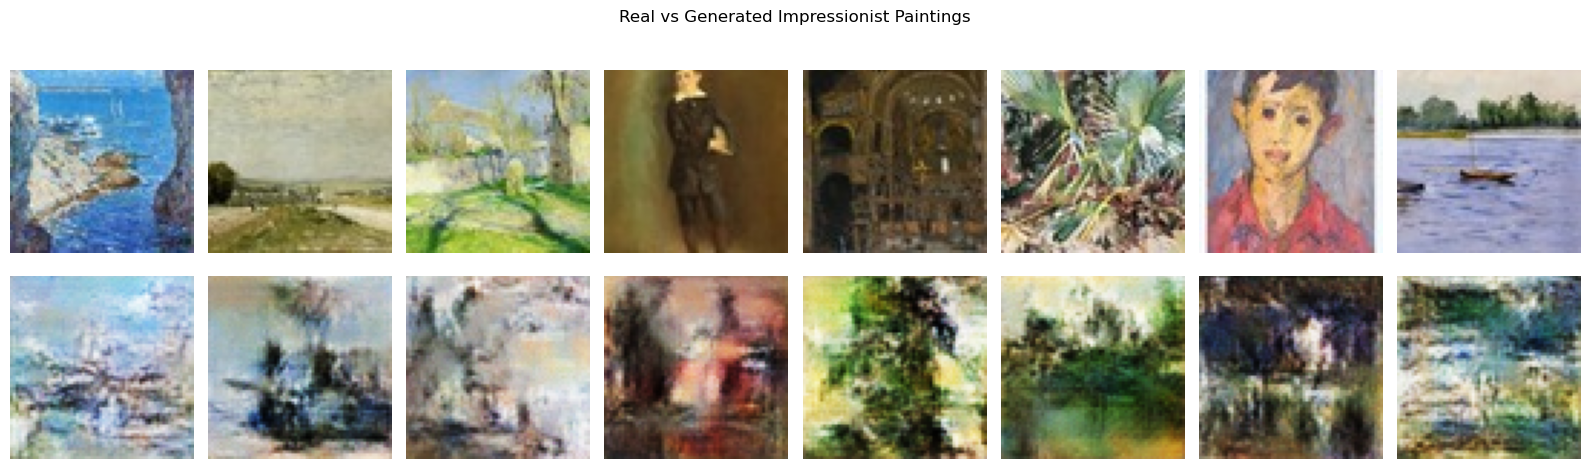

Part 4 completed.
Model: WGAN-GP V3
Selected epoch: 60
FID: 127.1088
Inception Score: 2.2022
Figures saved to: /home/zih050/private/results_v3


In [7]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import datasets, transforms
from torchvision.utils import save_image

# Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

root = Path("/home/zih050/private")
output_dir = root / "results_v3"
data_dir = root / "wikiart_small"

latent_dim = 128
seed = 285

# Generator architecture (same as V3)
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),

            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


# Load selected V3 checkpoint
G = Generator().to(device)

checkpoint_path = output_dir / "selected_generator.pt"

if not checkpoint_path.exists():
    checkpoint_path = output_dir / "wgan_gp_epoch_60.pt"

state = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

assert state["epoch"] == 60, "Expected V3 epoch-60 checkpoint."

G.load_state_dict(state["G"])
G.eval()

print("Loaded WGAN-GP V3, Epoch:", state["epoch"])

# Generate 16 paintings
z = torch.randn(
    16, latent_dim, 1, 1,
    generator=torch.Generator().manual_seed(seed + 2)
).to(device)

with torch.no_grad():
    generated = (G(z).cpu() + 1) / 2

# Plot generated images
fig, axes = plt.subplots(4, 4, figsize=(9, 9))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated[i].permute(1, 2, 0).clamp(0, 1)
    )
    ax.axis("off")

plt.suptitle("Generated Impressionist Paintings - WGAN-GP")
plt.tight_layout()

plt.savefig(
    output_dir / "generated_paintings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

save_image(
    generated,
    output_dir / "generated_grid.png",
    nrow=4
)

# Load real test paintings
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,) * 3, (0.5,) * 3)
])

test_dataset = datasets.ImageFolder(
    data_dir / "test",
    transform=transform
)

# Select 8 real paintings reproducibly
rng = torch.Generator().manual_seed(seed)
indices = torch.randperm(
    len(test_dataset),
    generator=rng
)[:8]

real = torch.stack([
    test_dataset[i.item()][0] for i in indices
])

real = (real + 1) / 2

# Compare real and generated paintings
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):
    axes[0, i].imshow(
        real[i].permute(1, 2, 0).clamp(0, 1)
    )

    axes[1, i].imshow(
        generated[i].permute(1, 2, 0).clamp(0, 1)
    )

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Real", fontsize=12)
axes[1, 0].set_ylabel("Generated", fontsize=12)

plt.suptitle("Real vs Generated Impressionist Paintings")
plt.tight_layout()

plt.savefig(
    output_dir / "real_vs_generated.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Part 4 completed.")
print("Model: WGAN-GP V3")
print("Selected epoch: 60")
print("FID: 127.1088")
print("Inception Score: 2.2022")
print("Figures saved to:", output_dir)